In [1]:
"""
Gasoline vs Electricity: US average monthly prices, 1978-11 to 2022-12.

Covers:
  1. Model deployment basics (saving/loading with joblib and pickle)
  2. Activation functions and a perceptron
  3. Loss functions, forward/backward propagation, SGD and Adam
  4. A neural network built from scratch in NumPy

Note: the CSV does not state its units. Gasoline is assumed to be $/gallon and
Electricity $/kWh. Check the dataset's source before reporting numbers.
"""
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

DATA = Path("/mnt/user-data/uploads/Gasoline_vs_Electricity_cost_over_time_-_US_Average.csv")
OUT = Path("/mnt/user-data/outputs")
OUT.mkdir(parents=True, exist_ok=True)

CUTOFF = "2010-01-01"        # time-based split: never shuffle a time series before splitting
rng = np.random.default_rng(0)


In [2]:
# =====================================================================
# 0. Load and clean


In [3]:
# =====================================================================
df = pd.read_csv(DATA).dropna(how="all")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
df["Electricity"] = df["Electricity"].interpolate()   # one missing value in the file


def metrics(y, p):
    return {"MAE": round(float(np.mean(np.abs(y - p))), 4),
            "RMSE": round(float(np.sqrt(np.mean((y - p) ** 2))), 4)}


def regression_table(df, n_lags=3):
    """Predict this month's gasoline price from the previous n_lags months."""
    d = pd.DataFrame({"Date": df["Date"], "y": df["Gasoline"]})
    for k in range(1, n_lags + 1):
        d[f"gas_lag{k}"] = df["Gasoline"].shift(k)
    d["elec_lag1"] = df["Electricity"].shift(1)
    return d.dropna().reset_index(drop=True)


reg = regression_table(df)
FEATS = ["gas_lag1", "gas_lag2", "gas_lag3", "elec_lag1"]
tr = reg[reg.Date < CUTOFF]
te = reg[reg.Date >= CUTOFF]
X_tr, y_tr = tr[FEATS].values, tr["y"].values
X_te, y_te = te[FEATS].values, te["y"].values


In [4]:
# =====================================================================
# 1. Deployment basics: train, save with joblib and pickle, reload, predict


In [5]:
# =====================================================================
lr_model = LinearRegression().fit(X_tr, y_tr)
print("Persistence baseline (predict last month):", metrics(y_te, X_te[:, 0]))
print("Linear regression (test):                 ", metrics(y_te, lr_model.predict(X_te)))

joblib.dump(lr_model, OUT / "gasoline_lr.joblib")          # efficient for NumPy-heavy objects
with open(OUT / "gasoline_lr.pkl", "wb") as f:              # standard library, works for anything
    pickle.dump(lr_model, f)

m_joblib = joblib.load(OUT / "gasoline_lr.joblib")
with open(OUT / "gasoline_lr.pkl", "rb") as f:
    m_pickle = pickle.load(f)   # only unpickle files you trust: pickle can run code on load

assert np.allclose(m_joblib.predict(X_te), lr_model.predict(X_te))
assert np.allclose(m_pickle.predict(X_te), lr_model.predict(X_te))
print("joblib and pickle round-trips reproduce predictions exactly.")


def predict_next_gas_price(model, gas_last3, elec_last):
    """Serving-style wrapper: validates input and builds features in training order."""
    if len(gas_last3) != 3:
        raise ValueError("expected the last 3 gasoline prices, most recent first")
    x = np.array([[*gas_last3, elec_last]], dtype=float)
    return float(model.predict(x)[0])


print("Example served prediction:",
      round(predict_next_gas_price(m_joblib, X_te[0, :3], X_te[0, 3]), 3))


Persistence baseline (predict last month): {'MAE': 0.1269, 'RMSE': 0.174}
Linear regression (test):                  {'MAE': 0.1153, 'RMSE': 0.1587}
joblib and pickle round-trips reproduce predictions exactly.
Example served prediction: 2.613


In [6]:
# =====================================================================
# 2. Activation functions and a perceptron


In [7]:
# =====================================================================
def step(z):
    return np.where(z >= 0, 1.0, 0.0)


def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


def tanh(z):
    return np.tanh(z)


def relu(z):
    return np.maximum(0.0, z)


ACTS = {  # name: (f, f')
    "sigmoid": (sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))),
    "tanh": (tanh, lambda z: 1 - np.tanh(z) ** 2),
    "relu": (relu, lambda z: (z > 0).astype(float)),
}

z_grid = np.linspace(-3, 3, 7)
print("\nActivation values on z =", z_grid)
for name, (f, fprime) in ACTS.items():
    print(f"  {name:8s} f(z)  = {np.round(f(z_grid), 3)}")
    print(f"  {'':8s} f'(z) = {np.round(fprime(z_grid), 3)}")

# Binary target: did gasoline rise this month? Features: earlier monthly returns.
ret = pd.DataFrame({"Date": df["Date"],
                    "gas_ret": df["Gasoline"].pct_change(),
                    "elec_ret": df["Electricity"].pct_change()})
cls = pd.DataFrame({"Date": ret["Date"],
                    "y_up": (ret["gas_ret"] > 0).astype(float),
                    "gas_ret_l1": ret["gas_ret"].shift(1),
                    "gas_ret_l2": ret["gas_ret"].shift(2),
                    "elec_ret_l1": ret["elec_ret"].shift(1)}).dropna().reset_index(drop=True)
CFEATS = ["gas_ret_l1", "gas_ret_l2", "elec_ret_l1"]
ctr = cls[cls.Date < CUTOFF]
cte = cls[cls.Date >= CUTOFF]


def fit_scaler(X):
    return X.mean(0), X.std(0) + 1e-12


def scale(X, mu, sd):
    return (X - mu) / sd


cmu, csd = fit_scaler(ctr[CFEATS].values)          # training statistics only
Xc_tr = scale(ctr[CFEATS].values, cmu, csd)
yc_tr = ctr["y_up"].values
Xc_te = scale(cte[CFEATS].values, cmu, csd)
yc_te = cte["y_up"].values


class Perceptron:
    """Rosenblatt perceptron: step activation, error-driven weight updates."""

    def __init__(self, lr=0.1, epochs=100):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.mistakes = []
        for _ in range(self.epochs):
            m = 0
            for xi, yi in zip(X, y):
                err = yi - step(xi @ self.w + self.b)
                if err != 0:
                    self.w += self.lr * err * xi
                    self.b += self.lr * err
                    m += 1
            self.mistakes.append(m)
            if m == 0:          # a full pass with no mistakes: data is linearly separable
                break
        return self

    def predict(self, X):
        return step(X @ self.w + self.b)


perc = Perceptron(lr=0.1, epochs=100).fit(Xc_tr, yc_tr)
print("\nPerceptron converged:", perc.mistakes[-1] == 0,
      "| epochs run:", len(perc.mistakes))
print("Mistakes in last 5 epochs:", perc.mistakes[-5:])
print("Train acc:", round((perc.predict(Xc_tr) == yc_tr).mean(), 3),
      "| Test acc:", round((perc.predict(Xc_te) == yc_te).mean(), 3))
print("Majority-class test acc:", round(max(yc_te.mean(), 1 - yc_te.mean()), 3))



Activation values on z = [-3. -2. -1.  0.  1.  2.  3.]
  sigmoid  f(z)  = [0.047 0.119 0.269 0.5   0.731 0.881 0.953]
           f'(z) = [0.045 0.105 0.197 0.25  0.197 0.105 0.045]
  tanh     f(z)  = [-0.995 -0.964 -0.762  0.     0.762  0.964  0.995]
           f'(z) = [0.01  0.071 0.42  1.    0.42  0.071 0.01 ]
  relu     f(z)  = [0. 0. 0. 0. 1. 2. 3.]
           f'(z) = [0. 0. 0. 0. 1. 1. 1.]

Perceptron converged: False | epochs run: 100
Mistakes in last 5 epochs: [165, 162, 151, 151, 154]
Train acc: 0.361 | Test acc: 0.34
Majority-class test acc: 0.538


In [8]:
# =====================================================================
# 3. Loss functions, forward/backward propagation, optimizers


In [9]:
# =====================================================================
def mse_loss(yhat, y):
    """Mean squared error and its gradient w.r.t. the prediction."""
    n = len(y)
    diff = yhat - y
    return np.mean(diff ** 2), 2 * diff / n


def bce_with_logits(logit, y):
    """Binary cross-entropy on raw logits. Gradient w.r.t. the logit is (p - y) / n."""
    n = len(y)
    p = sigmoid(logit)
    eps = 1e-12
    loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
    return loss, (p - y) / n


class MLP:
    """Input -> Dense(hidden) -> activation -> Dense(out), linear output."""

    def __init__(self, n_in, n_hidden, n_out=1, activation="tanh", seed=0):
        r = np.random.default_rng(seed)
        self.f, self.df = ACTS[activation]
        self.params = {
            "W1": r.normal(0, np.sqrt(1 / n_in), (n_in, n_hidden)),   # scaled init
            "b1": np.zeros(n_hidden),
            "W2": r.normal(0, np.sqrt(1 / n_hidden), (n_hidden, n_out)),
            "b2": np.zeros(n_out),
        }
        self.cache = None

    def forward(self, X):
        P = self.params
        z1 = X @ P["W1"] + P["b1"]        # affine
        a1 = self.f(z1)                   # non-linearity
        out = a1 @ P["W2"] + P["b2"]      # affine output
        self.cache = (X, z1, a1)          # save what backprop needs
        return out

    def backward(self, dout):
        """Chain rule from the output back to every parameter."""
        X, z1, a1 = self.cache
        P = self.params
        grads = {}
        grads["W2"] = a1.T @ dout
        grads["b2"] = dout.sum(axis=0)
        da1 = dout @ P["W2"].T
        dz1 = da1 * self.df(z1)
        grads["W1"] = X.T @ dz1
        grads["b1"] = dz1.sum(axis=0)
        return grads


class SGD:
    """Stochastic gradient descent with optional momentum."""

    def __init__(self, lr=0.01, momentum=0.9):
        self.lr, self.mom, self.v = lr, momentum, {}

    def step(self, params, grads):
        for k in params:
            v = self.mom * self.v.get(k, 0.0) - self.lr * grads[k]
            self.v[k] = v
            params[k] += v


class Adam:
    """Adam: per-parameter step sizes from running estimates of the gradient mean and variance."""

    def __init__(self, lr=1e-2, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.t, self.m, self.v = 0, {}, {}

    def step(self, params, grads):
        self.t += 1
        for k in params:
            g = grads[k]
            self.m[k] = self.b1 * self.m.get(k, 0.0) + (1 - self.b1) * g
            self.v[k] = self.b2 * self.v.get(k, 0.0) + (1 - self.b2) * g * g
            m_hat = self.m[k] / (1 - self.b1 ** self.t)     # bias correction
            v_hat = self.v[k] / (1 - self.b2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


def train(model, opt, X, y, loss_fn, epochs=200, batch=32, seed=0):
    r = np.random.default_rng(seed)
    history = []
    for _ in range(epochs):
        idx = r.permutation(len(X))
        for s in range(0, len(X), batch):
            b = idx[s:s + batch]
            out = model.forward(X[b])               # forward pass
            _, dout = loss_fn(out, y[b])            # loss and its gradient
            opt.step(model.params, model.backward(dout))   # backward pass + update
        history.append(loss_fn(model.forward(X), y)[0])
    return history


def gradient_check(model, X, y, loss_fn, eps=1e-6, seed=0):
    """Compare backprop to finite differences on one random entry per parameter."""
    r = np.random.default_rng(seed)
    _, dout = loss_fn(model.forward(X), y)
    grads = model.backward(dout)
    worst = 0.0
    for name, P in model.params.items():
        idx = tuple(r.integers(s) for s in P.shape)
        orig = P[idx]
        P[idx] = orig + eps
        up = loss_fn(model.forward(X), y)[0]
        P[idx] = orig - eps
        dn = loss_fn(model.forward(X), y)[0]
        P[idx] = orig
        num, ana = (up - dn) / (2 * eps), grads[name][idx]
        worst = max(worst, abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
    return worst


# Sanity-check backprop on a small random batch before trusting it
Xs = rng.normal(size=(20, 4))
ys = rng.normal(size=(20, 1))
chk = MLP(4, 5, 1, activation="tanh", seed=1)
print("\nGradient check, MSE (relative error, want < 1e-6):",
      f"{gradient_check(chk, Xs, ys, mse_loss):.2e}")
ys_bin = (ys > 0).astype(float)
print("Gradient check, BCE (relative error, want < 1e-6):",
      f"{gradient_check(chk, Xs, ys_bin, bce_with_logits):.2e}")



Gradient check, MSE (relative error, want < 1e-6): 3.67e-10
Gradient check, BCE (relative error, want < 1e-6): 3.64e-10


In [10]:
# =====================================================================
# 4. Neural network from scratch: predict next-month gasoline price


In [11]:
# =====================================================================
# Standardize with training statistics only
mu, sd = X_tr.mean(0), X_tr.std(0)
ymu, ysd = y_tr.mean(), y_tr.std()
Xtr_s, Xte_s = (X_tr - mu) / sd, (X_te - mu) / sd
ytr_s = ((y_tr - ymu) / ysd).reshape(-1, 1)


def run_regression(opt, hidden=16, activation="tanh", epochs=300):
    model = MLP(Xtr_s.shape[1], hidden, 1, activation=activation, seed=0)
    hist = train(model, opt, Xtr_s, ytr_s, mse_loss, epochs=epochs, batch=32)
    pred = model.forward(Xte_s).ravel() * ysd + ymu   # undo scaling -> file units
    return model, hist, pred


m_adam, h_adam, p_adam = run_regression(Adam(lr=1e-2))
m_sgd, h_sgd, p_sgd = run_regression(SGD(lr=1e-2, momentum=0.9))
print("\nNumPy MLP + Adam (test):    ", metrics(y_te, p_adam))
print("NumPy MLP + SGD  (test):    ", metrics(y_te, p_sgd))
print("Linear regression (test):   ", metrics(y_te, lr_model.predict(X_te)))

cls_model = MLP(Xc_tr.shape[1], 8, 1, activation="tanh", seed=0)
h_cls = train(cls_model, Adam(lr=1e-2), Xc_tr, yc_tr.reshape(-1, 1),
              bce_with_logits, epochs=200)
pred_cls = (cls_model.forward(Xc_te) > 0).ravel().astype(float)
print("NumPy MLP + BCE up/down test acc:", round((pred_cls == yc_te).mean(), 3),
      "(perceptron:", round((perc.predict(Xc_te) == yc_te).mean(), 3), ")")

# Save the from-scratch model: raw weights plus the scalers needed to serve it
np.savez(OUT / "numpy_mlp_weights.npz", **m_adam.params)
np.savez(OUT / "numpy_mlp_scalers.npz", mu=mu, sd=sd, ymu=ymu, ysd=ysd)



NumPy MLP + Adam (test):     {'MAE': 0.2588, 'RMSE': 0.3742}
NumPy MLP + SGD  (test):     {'MAE': 0.2141, 'RMSE': 0.317}
Linear regression (test):    {'MAE': 0.1153, 'RMSE': 0.1587}
NumPy MLP + BCE up/down test acc: 0.686 (perceptron: 0.34 )


In [12]:
# =====================================================================
# Plots


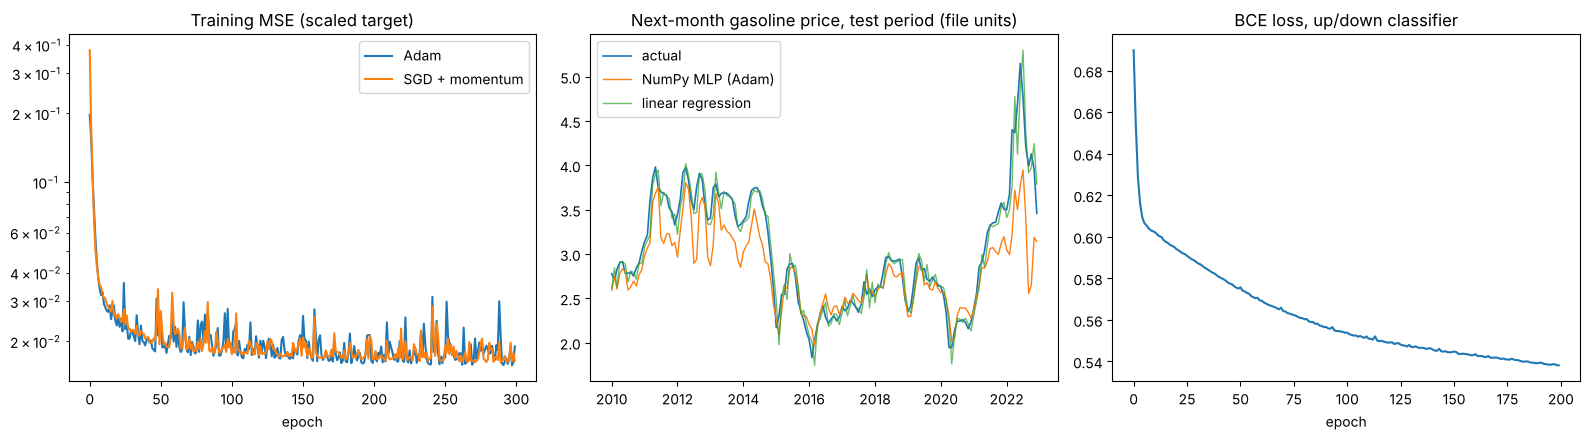


Saved outputs to /mnt/user-data/outputs


In [13]:
# =====================================================================
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(h_adam, label="Adam")
ax[0].plot(h_sgd, label="SGD + momentum")
ax[0].set(title="Training MSE (scaled target)", xlabel="epoch", yscale="log")
ax[0].legend()
ax[1].plot(te.Date, y_te, label="actual", lw=1.2)
ax[1].plot(te.Date, p_adam, label="NumPy MLP (Adam)", lw=1)
ax[1].plot(te.Date, lr_model.predict(X_te), label="linear regression", lw=1, alpha=0.7)
ax[1].set(title="Next-month gasoline price, test period (file units)")
ax[1].legend()
ax[2].plot(h_cls)
ax[2].set(title="BCE loss, up/down classifier", xlabel="epoch")
fig.tight_layout()
fig.savefig(OUT / "nn_training_results.png", dpi=120)
plt.show()
print("\nSaved outputs to", OUT)
